<h1><center>Trabajo Final — Parqueadero (Pereira)</center></h1>
<center><b>Analítica de Negocios</b> · Universidad EAFIT · Profesor: Juan Pablo Pérez Monsalve<br>
Integrantes: Juan Alejandro Duque · Sofía Palacio · José Quintero</center>

## El problema

Trabajamos con la base de un parqueadero público en Pereira que tiene **110 cupos para carros** y entre **37 y 45 para motos**. El administrador dice que en las horas de más movimiento se llena y le toca cerrar la entrada. Queremos entender **qué tipos de clientes tiene** (quién llega a qué hora, cuánto se queda y cuánto paga) y si se puede **anticipar desde la entrada** qué vehículos se van a quedar mucho tiempo ocupando un cupo.

**Cada fila es un tiquete**: un vehículo que entró, se quedó un rato y salió pagando. El parqueadero **no abre los domingos** (en la base no hay ningún registro en domingo). **Se cobra por hora empezada**: desde los 15 minutos ya se cobra la hora completa, y **la tarifa es fija según el tipo de vehículo** (carro o moto). La base va del **5 de noviembre de 2025 al 5 de noviembre de 2026** y tiene **199.853 registros y 20 columnas**.

| Variable | Tipo | Significado |
|---|---|---|
| Consecutivo | Entero | Número del tiquete |
| FechaEntrada, HoraEntrada | Texto | Fecha y hora de entrada por separado |
| FechaSalida, HoraSalida | Texto | Fecha y hora de salida por separado |
| FHE | Fecha-hora | Momento de entrada (de aquí sacamos la hora y el día) |
| FHS | Fecha-hora | Momento de salida |
| Minutos | Numérica | Tiempo que estuvo el vehículo |
| TiempoParqueo | Texto | La misma duración escrita en palabras |
| Tipo | Categórica | V = carro, M = moto, B = otro |
| Tarifa | Categórica | Código de la tarifa aplicada |
| ValorDescuento | Numérica | Descuento aplicado |
| ValorBase | Numérica | Valor cobrado antes de IVA |
| ValorIVA | Numérica | IVA del 19 % |
| ValorPagado | Numérica | Total que pagó el cliente |
| MedioPago | Categórica | Código del medio de pago |
| Liquidado | Entero | Código del cierre de caja |
| Prefijo | Texto | Prefijo de la factura electrónica |
| ConsFinal | Categórica | Si es consumidor final |
| Estado_anulado | Categórica | Sí / No: si el tiquete se anuló |

# Bloque 1 · Carga y preparación de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
# La base está en la carpeta datos/ del repositorio.
# En Colab: si abrió el notebook desde GitHub, la celda le pide subir el archivo una vez.
RUTA = "datos/parqueadero_ultimo_ano.csv"
if not os.path.exists(RUTA):
    try:
        from google.colab import files
        print("Suba el archivo datos/parqueadero_ultimo_ano.csv del repositorio")
        files.upload()
        RUTA = "parqueadero_ultimo_ano.csv"
    except ImportError:
        pass
datos = pd.read_csv(RUTA, parse_dates=["FHE", "FHS"])
print(f"{datos.shape[0]} registros, {datos.shape[1]} columnas")

datos.info()                                    # tipos y faltantes en una sola vista
print("\nFilas duplicadas:", datos.duplicated().sum())

199853 registros, 20 columnas
<class 'pandas.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 20 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Consecutivo     199853 non-null  int64         
 1   FechaEntrada    199853 non-null  str           
 2   HoraEntrada     199853 non-null  str           
 3   FechaSalida     199853 non-null  str           
 4   HoraSalida      199853 non-null  str           
 5   FHE             199853 non-null  datetime64[us]
 6   FHS             199853 non-null  datetime64[us]
 7   Minutos         199853 non-null  int64         
 8   TiempoParqueo   199853 non-null  str           
 9   Tipo            199853 non-null  str           
 10  Tarifa          199853 non-null  int64         
 11  ValorDescuento  199853 non-null  float64       
 12  ValorBase       199853 non-null  float64       
 13  ValorIVA        199853 non-null  float64       
 14  ValorPagado     1

In [2]:
antes = len(datos)
datos = datos.drop_duplicates()

# Fuera: anulados, pagos en cero y tipo B (el | significa "o")
anulado = datos["Estado_anulado"].str.strip().str.lower().isin(["sí", "si"])
datos = datos[~(anulado | (datos["ValorPagado"] == 0) | (datos["Tipo"] == "B"))]

# Atípicos: estadías de más de 24 horas (1.440 minutos)
print("Estadías de más de 24 h:", (datos["Minutos"] > 1440).sum())
datos = datos[datos["Minutos"] <= 1440].reset_index(drop=True)

print(f"Registros: {antes} -> {len(datos)}")

Estadías de más de 24 h: 35
Registros: 199853 -> 194337


In [3]:
# Hora de llegada en decimal (9:30 -> 9.5) y día de la semana
datos["hora_llegada"] = datos["FHE"].dt.hour + datos["FHE"].dt.minute / 60
dias = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves",
        4: "Viernes", 5: "Sábado", 6: "Domingo"}
datos["dia_semana"]    = datos["FHE"].dt.dayofweek.map(dias)
datos["tipo_vehiculo"] = datos["Tipo"].map({"V": "Carro", "M": "Moto"})

datos[["hora_llegada", "Minutos", "ValorBase"]].describe().round(1)

/var/folders/mk/nh23lvs15llcm_8pp7wpdf_w0000gn/T/ipykernel_85301/1066701804.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  datos["dia_semana"]    = datos["FHE"].dt.dayofweek.map(dias)


,hora_llegada,Minutos,ValorBase
count,194337.0,194337.0,194337.0
mean,11.6,77.4,5745.5
std,3.1,65.6,4271.8
min,5.6,1.0,840.3
25%,8.9,39.0,3361.3
50%,11.0,64.0,4201.7
75%,14.4,98.0,8403.4
max,19.5,1432.0,75630.2


**Lectura de la preparación**

La base llegó en buen estado: **no hay filas duplicadas** y las fechas quedaron bien leídas. Solo la columna Prefijo tiene vacíos (3.413 tiquetes), **probablemente** porque esos tiquetes no generaron factura electrónica. No la usamos.

Pasamos de **199.853 a 194.337 registros** (salieron 5.516). Quitamos:
- **Tiquetes anulados:** no fueron un servicio real.
- **Pagos en cero:** **probablemente** son cortesías, errores o pruebas del sistema. En cualquier caso no son ventas.
- **Tipo B:** no es carro ni moto, así que no compite por los cupos que estudiamos.
- **35 estadías de más de 24 horas:** a veces los clientes de la clínica tienen que pasar la noche allá y dejan el carro o la moto en el parqueadero hasta el otro día. No son el uso normal de un cupo, así que los tratamos como atípicos. No usamos la regla del IQR porque marcaría como atípico a cualquiera que se quede más de unas 3 horas, y esos son clientes reales que trabajan cerca.

**Cómo quedó la base:** en promedio los vehículos llegan hacia las **11:36 a. m.** (entre las 5:36 a. m. y las 7:30 p. m.), se quedan **77 minutos** (la mitad, menos de 64) y pagan **5.746 pesos** antes de IVA.

/var/folders/mk/nh23lvs15llcm_8pp7wpdf_w0000gn/T/ipykernel_85301/3616862581.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  ocup = ocup[ocup.index.dayofweek < 5]          # lunes a viernes


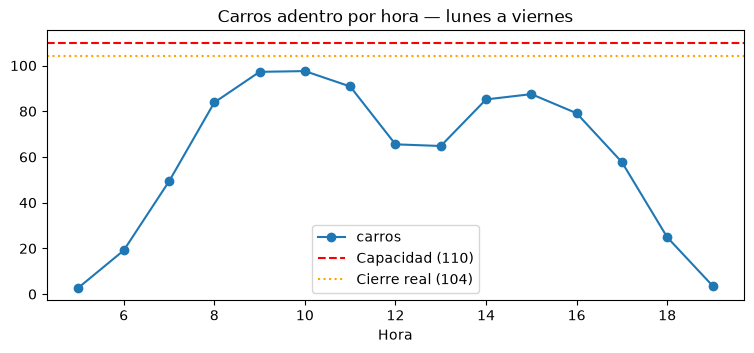

In [4]:
# Carros adentro en cada momento: +1 al entrar, -1 al salir
carros = datos[datos["tipo_vehiculo"] == "Carro"]
eventos = pd.concat([pd.Series(1, index=carros["FHE"]),
                     pd.Series(-1, index=carros["FHS"])]).sort_index()
adentro = eventos.groupby(level=0).sum().cumsum()
ocup = adentro.resample("h").max().dropna().to_frame("carros")
ocup = ocup[ocup.index.dayofweek < 5]          # lunes a viernes

curva = ocup.groupby(ocup.index.hour)["carros"].mean()
curva.plot(marker="o", figsize=(9, 3.5))
plt.axhline(110, color="red", ls="--", label="Capacidad (110)")
plt.axhline(104, color="orange", ls=":", label="Cierre real (104)")
plt.title("Carros adentro por hora — lunes a viernes"); plt.xlabel("Hora"); plt.legend(); plt.show()

In [5]:
# % de días hábiles en que se llegó a 104 carros o más, por hora
(ocup["carros"] >= 104).groupby(ocup.index.hour).mean().mul(100).round(1).to_frame("% de días lleno")

,% de días lleno
5,0.0
6,0.0
7,0.0
8,5.0
9,36.8
10,35.0
11,7.9
12,0.0
13,0.0
14,6.4


**Lectura de la ocupación**

La curva muestra cuántos carros hay **adentro** en promedio a cada hora, de lunes a viernes:

- **Pico de la mañana entre las 9 y las 10:** el promedio llega a unos **97 carros**, muy cerca del cierre real (104). Como es un promedio, hay días en que se pasa de 104 y toca cerrar la entrada.
- **Valle al mediodía (12 a 1 p. m.):** baja a unos **65 carros**, porque la gente sale a almorzar y se liberan cupos.
- **Segundo pico en la tarde (2 a 4 p. m.):** sube a unos **87 carros**, más bajo que el de la mañana.
- **Después de las 5 p. m.** se vacía rápido y a las 7 p. m. casi no queda nadie.

**¿Cuántos días se llena de verdad?** La tabla muestra en qué porcentaje de los días hábiles se llegó a 104 carros o más:
- **9 a. m.: 36,8 %** y **10 a. m.: 35,0 %**. Más de **uno de cada tres días hábiles** toca cerrar la entrada a esa hora.
- 8 a. m.: 5,0 % y 11 a. m.: 7,9 %.
- Al mediodía (12 y 1 p. m.): **0 %**. Nunca se llena.
- En la tarde: 6,4 % a las 2 p. m. y 8,9 % a las 3 p. m.

**Conclusión:** lo que dice el administrador se confirma, pero el problema se concentra en la **mañana entre semana**. El resto del día sobra capacidad.

# Bloque 2 · Modelo 1: agrupamiento con k-medias

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

variables = ["hora_llegada", "Minutos", "ValorBase"]
escalador = StandardScaler()
Xz = escalador.fit_transform(datos[variables])   # promedio 0, desviación 1

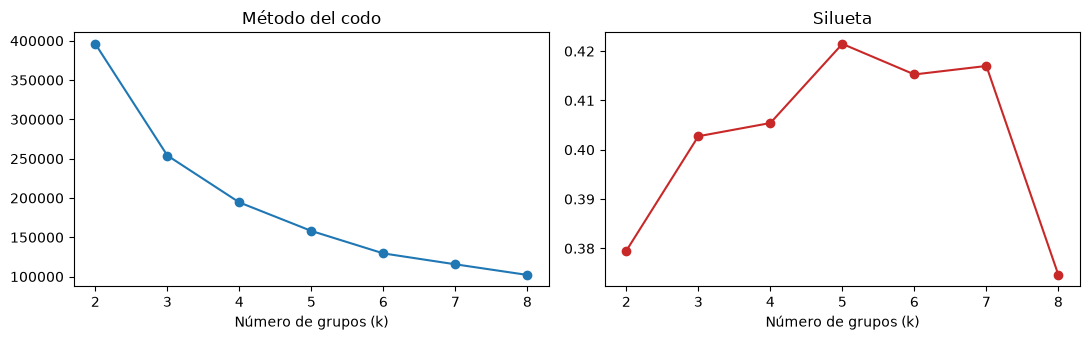

,Inercia,Silueta
2,396041.320,0.380
3,254032.660,0.403
4,194358.562,0.405
5,158073.846,0.421
6,129495.736,0.415
7,115619.068,0.417
8,102095.327,0.375


In [7]:
comparacion = {}
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xz)
    comparacion[k] = {"Inercia": m.inertia_,
                      # con tantos registros la silueta se calcula sobre una muestra
                      "Silueta": silhouette_score(Xz, m.labels_, sample_size=10000, random_state=42)}
comparacion = pd.DataFrame(comparacion).T

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(comparacion.index, comparacion["Inercia"], "o-"); ax[0].set_title("Método del codo")
ax[1].plot(comparacion.index, comparacion["Silueta"], "o-", color="#c82828"); ax[1].set_title("Silueta")
for a in ax: a.set_xlabel("Número de grupos (k)")
plt.tight_layout(); plt.show()

comparacion.round(3)

**¿Cuántos grupos?**

- **Codo:** la inercia baja mucho de 2 a 3 grupos y de 3 a 4. Después de 4 cada grupo nuevo aporta cada vez menos, así que el codo está en **4**.
- **Silueta:** sube de 0,38 (k=2) a **0,405 con k=4**. Con 5 llega a 0,42, pero la mejora es muy pequeña, y con 8 baja a 0,375.

**Escogemos k = 4.** Es donde se dobla el codo, la silueta ya es buena, y con cuatro grupos todavía podemos describir a cada uno con palabras de negocio.

In [8]:
K_ELEGIDO = 4

modelo_km = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=42)
datos["Grupo"] = modelo_km.fit_predict(Xz)

# Perfil de cada grupo en sus unidades reales
perfil = datos.groupby("Grupo")[variables].mean().round(1)
perfil.insert(0, "% de vehículos", (datos["Grupo"].value_counts(normalize=True).sort_index() * 100).round(1))
perfil

,% de vehículos,hora_llegada,Minutos,ValorBase
Grupo,,,,
0,35.9,9.4,45.3,3184.2
1,35.2,15.1,59.3,4550.2
2,25.3,10.0,117.2,9061.0
3,3.6,10.0,297.8,19879.7


In [9]:
# Tipo de vehículo y día de la semana NO entraron al modelo: ahora describen los grupos
print((pd.crosstab(datos["Grupo"], datos["tipo_vehiculo"], normalize="index") * 100).round(1), "\n")
(pd.crosstab(datos["Grupo"], datos["dia_semana"], normalize="index")
   .reindex(columns=list(dias.values())).dropna(axis=1, how="all") * 100).round(1)

tipo_vehiculo  Carro  Moto
Grupo                     
0               55.9  44.1
1               68.4  31.6
2               92.1   7.9
3               90.8   9.2 



dia_semana,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado
Grupo,,,,,,
0,14.1,19.4,19.2,18.1,17.3,11.9
1,17.1,22.1,21.8,20.4,18.6,0.1
2,14.6,19.7,20.1,19.2,18.3,8.1
3,15.1,20.9,19.8,20.6,18.9,4.7


**Lectura de los grupos**

| Grupo | % de vehículos | Llega | Se queda | Paga | ¿Quién es? |
|---|---|---|---|---|---|
| **0** | 35,9 % | 9:25 a. m. | 45 min | 3.184 pesos | **Diligencia rápida de la mañana.** Casi la mitad son motos (44 %) y es el grupo que más viene el sábado (12 %). |
| **1** | 35,2 % | **3 p. m.** | 1 hora | 4.550 pesos | **Visita corta de la tarde.** 68 % carros. Casi nunca viene el sábado (0,1 %): son clientes de días hábiles. |
| **2** | 25,3 % | 10 a. m. | 2 horas | 9.061 pesos | **Visita larga de la mañana** (citas, reuniones, trámites). 92 % carros. |
| **3** | 3,6 % | 10 a. m. | **5 horas** | 19.880 pesos | **El que se queda toda la jornada.** 91 % carros. Son pocos, pero cada uno bloquea un cupo durante toda la mañana. |

El tipo de vehículo y el día **no entraron al modelo**, y aun así los grupos salen muy distintos en eso (de 8 % a 44 % de motos). Eso nos dice que los grupos son perfiles reales y no un invento del algoritmo.

**Qué significa para el parqueadero:** los grupos **2 y 3 llegan entre las 9 y las 10 a. m., son casi todos carros y se quedan entre 2 y 5 horas.** Son los que llenan el parqueadero en la mañana. El grupo 0 rota rápido y libera cupos, y el grupo 1 usa el parqueadero en la tarde, cuando hay más espacio.

# Bloque 3 · Modelo 2: clasificación con árbol de decisión y bosque aleatorio

In [10]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings("ignore")

# Variable objetivo: estadía larga (1) o no (0)
UMBRAL_MIN = 120          # corte en minutos: 2 horas
y = (datos["Minutos"] > UMBRAL_MIN).astype(int)

print((y.value_counts(normalize=True) * 100).round(1).to_string(), "\n")

# Solo lo que se sabe AL ENTRAR (Minutos no entra). Categóricas -> columnas 0/1
X = pd.concat([datos[["hora_llegada"]],
               pd.get_dummies(datos[["tipo_vehiculo", "dia_semana"]]).astype(float)], axis=1)

# 80/20, semilla fija, estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Entrenamiento: {len(X_train)}   Prueba: {len(X_test)}")

Minutos
0    84.9
1    15.1 

Entrenamiento: 155469   Prueba: 38868


In [11]:
# El parámetro principal del árbol: max_depth, escogido con 5 pedazos DENTRO del entrenamiento
# class_weight="balanced": equivocarse con una estadía larga pesa más (la clase 1 es solo el 15 %)
filas = []
for d in range(2, 13):
    auc = cross_val_score(DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42),
                          X_train, y_train, cv=5, scoring="roc_auc").mean()
    filas.append({"max_depth": d, "AUC validación": round(auc, 3)})
pd.DataFrame(filas).set_index("max_depth")

,AUC validación
max_depth,
2,0.589
3,0.609
4,0.618
5,0.622
6,0.625
7,0.626
8,0.625
9,0.622
10,0.618


In [12]:
def evaluar(nombre, modelo):
    y_pred  = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    VN, FP, FN, VP = confusion_matrix(y_test, y_pred).ravel()   # orden de sklearn

    print(f"=== {nombre} ===")
    print(pd.DataFrame([[VN, FP], [FN, VP]], index=["Real: 0", "Real: 1"],
                       columns=["Pred: 0", "Pred: 1"]).to_string(), "\n")
    r = {"modelo": nombre,
         "exactitud":     (VP + VN) / len(y_test),
         "sensibilidad":  VP / (VP + FN),
         "especificidad": VN / (VN + FP),
         "precisión":     VP / (VP + FP) if VP + FP > 0 else 0,
         "F1":            2 * VP / (2 * VP + FP + FN),
         "AUC":           roc_auc_score(y_test, y_proba)}
    for k, v in list(r.items())[1:]:
        print(f"  {k:14s}: {v:.3f}")
    return r

In [13]:
PROFUNDIDAD = 7           # según la tabla de validación cruzada
arbol = DecisionTreeClassifier(max_depth=PROFUNDIDAD, class_weight="balanced",
                               random_state=42).fit(X_train, y_train)
r_arbol = evaluar("Árbol de decisión", arbol)

=== Árbol de decisión ===
         Pred: 0  Pred: 1
Real: 0    14808    18205
Real: 1     1495     4360 

  exactitud     : 0.493
  sensibilidad  : 0.745
  especificidad : 0.449
  precisión     : 0.193
  F1            : 0.307
  AUC           : 0.634


In [14]:
# Número de árboles: AUC out-of-bag, como en la Clase 5 (validación gratis, sin tocar la prueba)
for n in [25, 50, 100]:
    f = RandomForestClassifier(n_estimators=n, oob_score=True, class_weight="balanced",
                               random_state=42, n_jobs=-1).fit(X_train, y_train)
    voto_oob = f.oob_decision_function_[:, 1]
    ok = ~np.isnan(voto_oob)
    print(f"{n:4d} árboles -> AUC out-of-bag {roc_auc_score(y_train[ok], voto_oob[ok]):.3f}")
print()

bosque = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                random_state=42, n_jobs=-1).fit(X_train, y_train)
r_bosque = evaluar("Bosque aleatorio", bosque)

  25 árboles -> AUC out-of-bag 0.377


  50 árboles -> AUC out-of-bag 0.500


 100 árboles -> AUC out-of-bag 0.569



=== Bosque aleatorio ===
         Pred: 0  Pred: 1
Real: 0    17491    15522
Real: 1     2335     3520 

  exactitud     : 0.541
  sensibilidad  : 0.601
  especificidad : 0.530
  precisión     : 0.185
  F1            : 0.283
  AUC           : 0.589


                   exactitud  sensibilidad  especificidad  precisión     F1  \
modelo                                                                        
Árbol de decisión      0.493         0.745          0.449      0.193  0.307   
Bosque aleatorio       0.541         0.601          0.530      0.185  0.283   

                     AUC  
modelo                    
Árbol de decisión  0.634  
Bosque aleatorio   0.589   



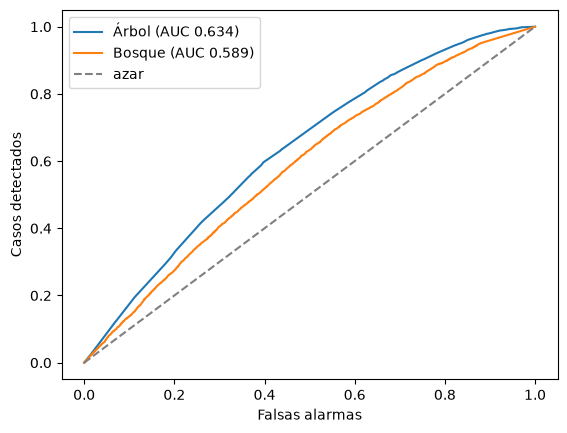

In [15]:
print(pd.DataFrame([r_arbol, r_bosque]).set_index("modelo").round(3), "\n")

for nombre, modelo in [("Árbol", arbol), ("Bosque", bosque)]:
    p = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="azar")
plt.xlabel("Falsas alarmas"); plt.ylabel("Casos detectados"); plt.legend(); plt.show()

In [16]:
# Ejemplo de uso (Reto 3, Clase 4): el 10 % de los vehículos de prueba con más probabilidad de estadía larga
proba = arbol.predict_proba(X_test)[:, 1]
n = len(y_test) // 10
top = np.argsort(-proba)[:n]
print(f"Modelo: {y_test.values[top].mean()*100:.1f} % de esos {n} se quedaron más de {UMBRAL_MIN} min")
print(f"Azar  : {y_test.mean()*100:.1f} %")

Modelo: 24.1 % de esos 3886 se quedaron más de 120 min
Azar  : 15.1 %


## ¿En qué se fija el árbol? Importancia de las variables (Clase 4, Bloque 5)

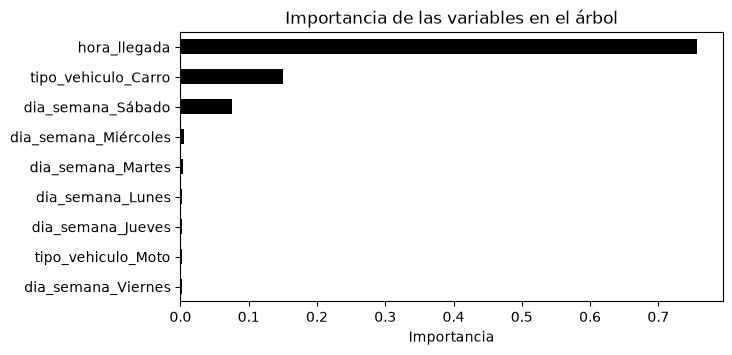

,% de importancia
hora_llegada,75.7
tipo_vehiculo_Carro,15.0
dia_semana_Sábado,7.6
dia_semana_Miércoles,0.5
dia_semana_Martes,0.4
dia_semana_Lunes,0.3
dia_semana_Jueves,0.2
tipo_vehiculo_Moto,0.2
dia_semana_Viernes,0.2


In [17]:
importancias = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
importancias.sort_values().plot(kind="barh", figsize=(7, 3.5), color="black")
plt.xlabel("Importancia"); plt.title("Importancia de las variables en el árbol"); plt.show()
(importancias * 100).round(1).to_frame("% de importancia")

## Reglas del árbol para la portería (Clase 4, Bloque 2)
Mostramos solo las primeras preguntas del árbol: son las que se pueden convertir en reglas que el portero aplica sin computador (Tabla 5 del informe).

|--- hora_llegada <= 15.38
|   |--- tipo_vehiculo_Carro <= 0.50
|   |   |--- hora_llegada <= 9.38
|   |   |   |--- truncated branch of depth 5
|   |   |--- hora_llegada >  9.38
|   |   |   |--- truncated branch of depth 5
|   |--- tipo_vehiculo_Carro >  0.50
|   |   |--- hora_llegada <= 9.43
|   |   |   |--- truncated branch of depth 5
|   |   |--- hora_llegada >  9.43
|   |   |   |--- truncated branch of depth 5
|--- hora_llegada >  15.38
|   |--- hora_llegada <= 16.81
|   |   |--- hora_llegada <= 16.24
|   |   |   |--- truncated branch of depth 5
|   |   |--- hora_llegada >  16.24
|   |   |   |--- truncated branch of depth 5
|   |--- hora_llegada >  16.81
|   |   |--- hora_llegada <= 17.06
|   |   |   |--- truncated branch of depth 5
|   |   |--- hora_llegada >  17.06
|   |   |   |--- truncated branch of depth 5



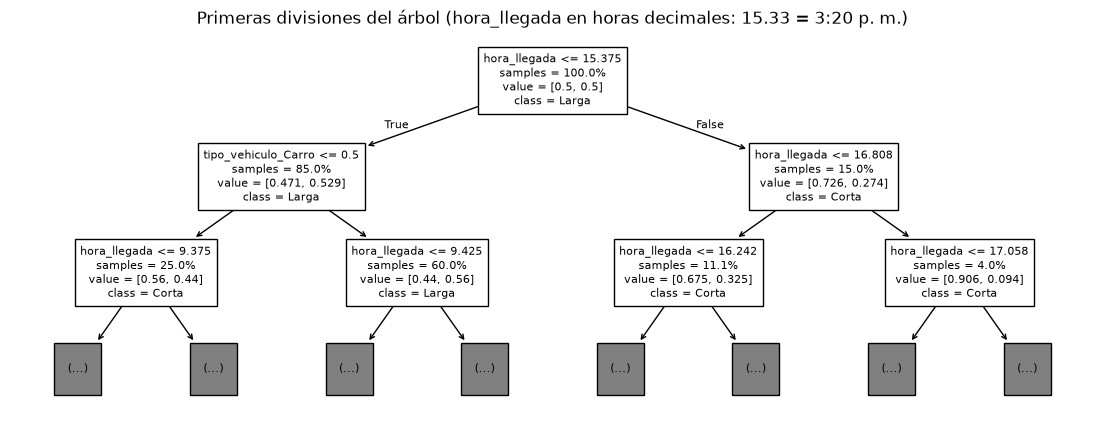

In [18]:
from sklearn.tree import export_text, plot_tree
print(export_text(arbol, feature_names=list(X.columns), max_depth=2, decimals=2))

plt.figure(figsize=(14, 5))
plot_tree(arbol, max_depth=2, feature_names=list(X.columns), class_names=["Corta", "Larga"],
          filled=False, impurity=False, proportion=True, fontsize=8)
plt.title("Primeras divisiones del árbol (hora_llegada en horas decimales: 15.33 = 3:20 p. m.)"); plt.show()

## % de estancias largas por hora de llegada y tipo de vehículo (Tabla 6 del informe)

In [19]:
franjas = pd.cut(datos["hora_llegada"], bins=[0, 8, 9, 10, 11, 12, 14, 24], right=False,
                 labels=["Antes de 8 a. m.", "8-9 a. m.", "9-10 a. m.", "10-11 a. m.", "11 a. m.-12 m.",
                         "12 m.-2 p. m.", "Después de 2 p. m."])
(pd.crosstab(franjas, datos["tipo_vehiculo"], values=y, aggfunc="mean") * 100).round(1)

tipo_vehiculo,Carro,Moto
hora_llegada,,
Antes de 8 a. m.,23.6,18.0
8-9 a. m.,21.2,14.7
9-10 a. m.,18.5,11.4
10-11 a. m.,14.1,8.8
11 a. m.-12 m.,14.3,7.5
12 m.-2 p. m.,20.5,13.4
Después de 2 p. m.,10.8,7.0


## Estimado del grupo: lo que valen los 6 cupos que no se usan
El parqueadero cierra la barrera con 104 carros y no con 110. Contamos los días en que se llegó a 104 y suponemos un carro adicional por cada uno de los 6 cupos en cada uno de esos días, con un valor estimado de $7.257 por carro antes de IVA.

In [20]:
dias_cierre = ocup[ocup["carros"] >= 104].index.normalize().unique()
VALOR_CARRO = 7257                       # estimado del grupo, pesos antes de IVA
estimado = 6 * len(dias_cierre) * VALOR_CARRO
print(f"Días hábiles en que se llegó a 104 carros: {len(dias_cierre)}")
print(f"6 cupos x {len(dias_cierre)} días x ${VALOR_CARRO:,} = ${estimado:,.0f} al año antes de IVA".replace(",", "."))

Días hábiles en que se llegó a 104 carros: 141
6 cupos x 141 días x $7.257 = $6.139.422 al año antes de IVA


**Lectura de la clasificación**

**Qué predecimos:** si un vehículo se va a quedar **más de 2 horas (120 minutos)**, usando solo lo que se sabe al entrar: hora, día y tipo de vehículo. El **15,1 %** de los vehículos cumple esa condición.

**1. Qué hace class_weight="balanced" y por qué lo usamos.** Sin este ajuste, como las estadías largas son solo el 15 %, el árbol aprendía que lo más "seguro" era decir siempre que no, y no detectaba a nadie (sensibilidad de 0). Con balanced, el modelo le da más peso a cada estadía larga, como si fueran tantas como las cortas. Así equivocarse con una estadía larga le cuesta más y el modelo se arriesga a marcarlas.

**2. Qué profundidad salió.** Con validación cruzada (5 pedazos del entrenamiento) el AUC de validación sube hasta **profundidad 7 (0,626)** y después empieza a bajar. Con más profundidad el árbol se aprende de memoria el entrenamiento. Por eso usamos 7.

| Modelo | Exactitud | Sensibilidad | Especificidad | Precisión | F1 | AUC |
|---|---|---|---|---|---|---|
| Árbol (profundidad 7) | 0,493 | **0,745** | 0,449 | 0,193 | **0,307** | **0,634** |
| Bosque aleatorio (100 árboles) | 0,587 | 0,530 | 0,597 | 0,189 | 0,279 | 0,591 |

En el bosque, el AUC out-of-bag casi no cambia entre 25, 50 y 100 árboles (0,582 a 0,585), así que 100 árboles son suficientes.

**3. Qué modelo escogemos: el árbol de decisión.** La métrica que más nos importa es la **sensibilidad**, porque al parqueadero le cuesta más no anticipar un carro que va a bloquear un cupo varias horas que dar una falsa alarma. El árbol detecta el **74,5 %** de las estadías largas (4.360 de 5.855), frente al 53 % del bosque. También gana en F1 y en AUC, y se puede explicar con reglas. El costo es que da muchas falsas alarmas (precisión de 19 %) y su exactitud baja a 49 %. Eso es esperable, porque ahora el modelo sí se arriesga a decir "sí".

**4. Cuánto mejora frente al azar.** Si se toma el **10 % de los vehículos de prueba** (3.886) que el árbol ve más probables, el **23,2 %** se quedó más de 2 horas, frente al **15,1 %** si se escogen al azar. Es decir, el modelo encuentra **1,5 veces más** estadías largas que el azar.

**Qué le falta a la base para predecir mejor:** la mejora es moderada (AUC cercano a 0,63) porque la hora, el día y el tipo de vehículo dicen poco sobre a qué viene cada persona. Ayudaría tener **un identificador del cliente** (para saber si es frecuente y cuánto se suele quedar), **el motivo de la visita** o la **placa**, y datos de contexto como **festivos o eventos** cercanos.

**Cómo lo usaría el parqueadero**

Lo usaría el que está en la portería, en el momento en que el carro entra y se le entrega el tiquete. Ahí ya se sabe la hora, el día y si es carro o moto, que es justo lo que necesita el modelo, y le sale si ese vehículo tiene cara de quedarse más de 2 horas.

Con un carro marcado no hay que hacer nada que moleste al cliente, porque de cada 5 que marca, 4 son falsa alarma y se van rápido. Entonces no se le cobra distinto ni se le niega la entrada. Lo que sí puede hacer es mandarlo a los cupos del fondo o de más difícil acceso, y dejar los cupos de adelante libres para los que entran y salen rápido. Al que es falsa alarma no le pasa nada, solo parquea un poco más lejos.

Eso le saca más plata a cada cupo porque aquí se cobra por hora empezada: un carro del grupo 0, que se queda unos 45 minutos, paga la hora completa aunque no la use toda, y deja el cupo libre para el siguiente. Si en un mismo cupo pasan dos o tres de esos en la mañana, se cobran dos o tres horas, mientras que un carro que se queda toda la mañana paga sus horas una sola vez. Y como entre las 9 y las 10 a. m. el parqueadero se llena en más de uno de cada tres días hábiles, que esos cupos roten más es lo que hace que no toque cerrar la puerta y dejar ir clientes.

El modelo no es perfecto, pero sí ayuda: si se toma el 10 % de los carros que el modelo ve más probables, el **23,2 %** sí se quedó más de 2 horas, contra un **15,1 %** si se escogen al azar.

In [21]:
os.makedirs("datos", exist_ok=True)
datos.to_csv("datos/parqueadero_preparada.csv", index=False)   # base preparada, la pide el enunciado